# Canais de cor RGB

In [ ]:
import sys
from pathlib import Path

RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

In [4]:
import cv2
from pathlib import Path

from src.leitura import PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem, nome_da_mascara
from src.preprocessamento import extrair_canais

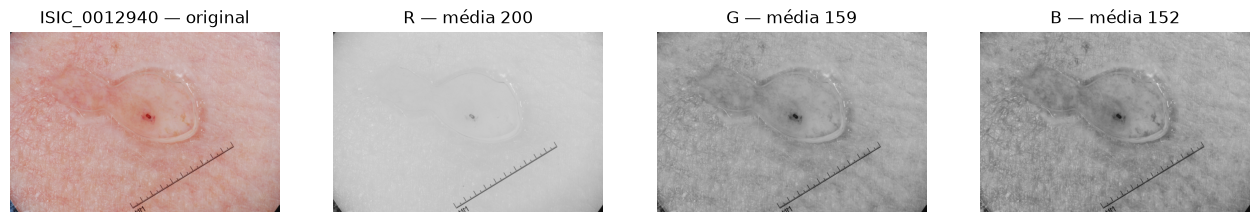

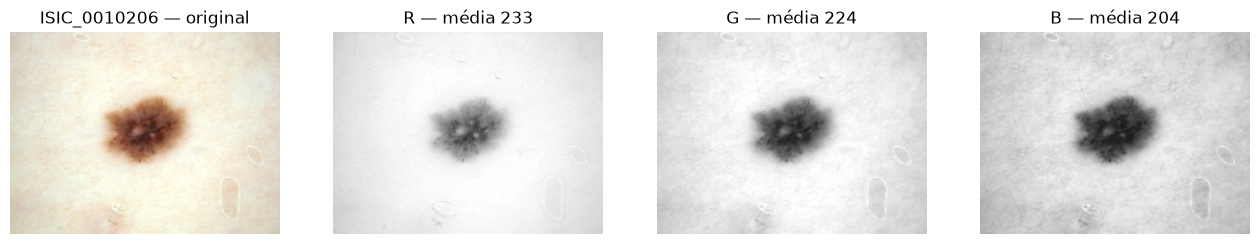

In [5]:
alvo = PASTA_RESULTADOS / "canais"

for nome in ["ISIC_0012940.jpg", "ISIC_0010206.jpg"]:   # a difícil + a fácil (metadata.csv)
    img = carregar_imagem(PASTA_IMAGENS / nome)
    r, g, b = extrair_canais(img)

    fig, axes = plt.subplots(1, 4, figsize=(16, 5))
    axes[0].imshow(img)                                  # original: SEM cmap (é RGB, 3 canais)
    axes[0].set_title(f"{Path(nome).stem} — original")
    for ax, canal, letra in zip(axes[1:], [r, g, b], ["R", "G", "B"]):
        ax.imshow(canal, cmap="gray", vmin=0, vmax=255)  # escala fixa = comparação honesta
        ax.set_title(f"{letra} — média {canal.mean():.0f}")
    for ax in axes:
        ax.axis("off")

    fig.savefig(alvo / f"{Path(nome).stem}_canais.png", bbox_inches="tight", dpi=150)
    plt.show()
    plt.close(fig)   # boa prática: fecha figura no loop para não acumular memória

In [6]:
# Média de cada canal DENTRO vs FORA da lesão, usando a máscara de referência
for nome in ["ISIC_0012940.jpg", "ISIC_0010206.jpg"]:
    img = carregar_imagem(PASTA_IMAGENS / nome)
    r, g, b = extrair_canais(img)
    msk = cv2.imread(str(nome_da_mascara(PASTA_IMAGENS / nome)), cv2.IMREAD_GRAYSCALE)

    print(f"--- {Path(nome).stem} ---")
    for canal, letra in zip([r, g, b], ["R", "G", "B"]):
        dentro = canal[msk > 0].mean()     # indexação booleana NumPy (slides 3_1!)
        fora = canal[msk == 0].mean()
        print(f"{letra}: lesão {dentro:.1f} | pele {fora:.1f} | pele - lesão {fora - dentro:+.1f}")

--- ISIC_0012940 ---
R: lesão 198.3 | pele 200.1 | pele - lesão +1.8
G: lesão 143.3 | pele 159.5 | pele - lesão +16.2
B: lesão 129.4 | pele 152.7 | pele - lesão +23.3
--- ISIC_0010206 ---
R: lesão 160.6 | pele 238.7 | pele - lesão +78.2
G: lesão 113.6 | pele 233.1 | pele - lesão +119.6
B: lesão 87.4 | pele 214.2 | pele - lesão +126.8
